# Functional Company Search with SBERT and Cosine Similarity

This project implements a natural language processing pipeline for **retrieving the most functionally similar companies** from a set of business descriptions using **SBERT embeddings** and **cosine similarity analysis**.

The goal is to input a **functional prompt** (e.g., "provides cybersecurity services" or "manufactures car parts") and retrieve companies whose business descriptions best match it. The model captures the meaning of both the descriptions and the prompt, so matches don't depend on shared keywords or industry codes.

**Objectives:**

- Extract and preprocess company business descriptions
- Generate sentence embeddings with SBERT
- Encode functional prompts into the same embedding space
- Calculate cosine similarity scores between prompts and business description sentences
- Retrieve and rank the top-matching companies
- Sanity check the results against GICS sectors

## 1. Setup and Imports

Import libraries and set up paths.

In [1]:
# Import required libraries
import logging
import os
import re

# Hide progress bars, the Hugging Face login nudge and a harmless torch warning on macOS
os.environ["TQDM_DISABLE"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import torch
import torch.nn.functional as F
from nltk.tokenize import sent_tokenize
from sentence_transformers import SentenceTransformer

# Download required NLTK data
_ = nltk.download("punkt_tab", quiet=True)

In [2]:
# Define the base directory (the notebook runs from notebooks/)
base_dir = os.path.dirname(os.path.abspath("."))

# Define subdirectories
data_dir = os.path.join(base_dir, "Data")
embeddings_dir = os.path.join(data_dir, "Embeddings")
images_dir = os.path.join(base_dir, "images")

# Create directories if they don't exist
os.makedirs(data_dir, exist_ok=True)
os.makedirs(embeddings_dir, exist_ok=True)
os.makedirs(images_dir, exist_ok=True)

# Define paths to save outputs
company_bd_data_path = os.path.join(data_dir, "company_bd_data.csv")
similarity_results_path = os.path.join(data_dir, "similarity_results.csv")
embedding_save_path = os.path.join(embeddings_dir, "bd_embeddings.pt")

## 2. Data Collection

I use two sources for business descriptions of public companies:

1. **Wikipedia**: the current list of Russell 1000 companies, their ticker symbols, and GICS sectors
2. **Yahoo Finance API (via yfinance)**: the long business description for each company

Yahoo Finance rate limited my original pull, so only part of the Russell 1000 came back, and almost all of it is companies starting with A to G. I saved that pull to `Data/company_bd_data.csv` and load it here. Set `REFRESH_DATA = True` to pull the data again (slow, and it can hit the same rate limit).

In [3]:
# Set to True to pull fresh data from Wikipedia and Yahoo Finance
REFRESH_DATA = False

if REFRESH_DATA:
    import yfinance as yf

    # Extract Russell 1000 tickers from Wikipedia
    url = "https://en.wikipedia.org/wiki/Russell_1000_Index"
    russell1000_table = pd.read_html(url)[3]

    # Replace periods with dashes (e.g., BRK.B -> BRK-B) as yfinance requires this format
    russell1000_table["Symbol"] = russell1000_table["Symbol"].str.replace(".", "-", regex=False)
    tickers = russell1000_table["Symbol"].tolist()

    # Use yfinance to extract business descriptions for each ticker
    bd_data = []
    errors = []
    for ticker in tickers:
        try:
            info = yf.Ticker(ticker).info
            bd_data.append({"Symbol": ticker, "long_bd": info.get("longBusinessSummary", "")})
        except Exception as e:
            errors.append({"Symbol": ticker, "error": str(e)})
    print(f"Number of errors: {len(errors)}")

    # Add business description data to the Russell 1000 table
    df = pd.merge(russell1000_table, pd.DataFrame(bd_data), on="Symbol", how="left")

    # Drop rows with missing or empty business descriptions
    df = df[df["long_bd"].fillna("").str.strip() != ""]

    # Clean up column names for consistency
    df.columns = df.columns.str.lower().str.replace(r"[ .\-]", "_", regex=True)

    # Save company business description data
    df.to_csv(company_bd_data_path, index=False)
else:
    df = pd.read_csv(company_bd_data_path)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 424 entries, 0 to 423
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   company            424 non-null    str  
 1   symbol             424 non-null    str  
 2   gics_sector        424 non-null    str  
 3   gics_sub_industry  342 non-null    str  
 4   long_bd            424 non-null    str  
dtypes: str(5)
memory usage: 16.7 KB


In [4]:
# Companies by first letter of the name
print(df["company"].str[0].str.upper().value_counts().sort_index().to_dict())

{'1': 1, '3': 1, 'A': 109, 'B': 46, 'C': 107, 'D': 42, 'E': 51, 'F': 38, 'G': 28, 'H': 1}


In [5]:
# Companies per sector
df["gics_sector"].value_counts()

gics_sector
Industrials               69
Financials                65
Information Technology    62
Consumer Discretionary    54
Health Care               48
Consumer Staples          27
Materials                 26
Real Estate               24
Utilities                 22
Energy                    17
Communication Services    10
Name: count, dtype: int64

In [6]:
# Display top rows
df.head()

,company,symbol,gics_sector,gics_sub_industry,long_bd
0,10x Genomics,TXG,Health Care,Health Care Technology,"10x Genomics, Inc., a life science technology ..."
1,3M,MMM,Industrials,Industrial Conglomerates,3M Company provides diversified technology ser...
2,A. O. Smith,AOS,Industrials,Building Products,A. O. Smith Corporation manufactures and marke...
3,AAON,AAON,Industrials,Building Products,"AAON, Inc., together with its subsidiaries, en..."
4,Abbott Laboratories,ABT,Health Care,Health Care Equipment,"Abbott Laboratories, together with its subsidi..."


## 3. Text Cleaning and Functional Filtering

I preprocess business descriptions to focus only on sentences that describe functional operations, removing generic or non-business information:

- Clean text by removing extra whitespace.
- Split descriptions into individual sentences.
- Expand the dataset to one row per sentence.
- Filter out sentences about locations, history, or organizational details. Phrases only match as whole words, so "cloud-based infrastructure" doesn't count as "based in".
- Keep only sentences that capture actual business activities.

In [7]:
# Clean text function
def clean_text(text: str) -> str:
    """Remove extra whitespace while preserving case."""
    return re.sub(r"\s+", " ", text).strip()

# Copy original dataframe and preprocess text
df_cleaned = df.copy()
df_cleaned["clean_long_bd"] = df_cleaned["long_bd"].apply(clean_text)
df_cleaned["sentences"] = df_cleaned["clean_long_bd"].apply(sent_tokenize)

# Expand each description into individual sentences
df_expanded = df_cleaned.explode("sentences").rename(
    columns={"sentences": "individual_sentence"}
).reset_index(drop=True)

print(f"Processed {len(df_cleaned)} companies into {len(df_expanded)} total sentences.")

Processed 424 companies into 2800 total sentences.


In [8]:
# List of phrases indicating non-functional sentences
NON_FUNCTION_KEYWORDS = [
    "headquartered in", "located in", "offices in", "based in", "established in",
    "founded in", "incorporated in", "previously known as", "formerly known as",
    "renamed to", "was founded"
]

# Match whole phrases only
NON_FUNCTION_PATTERN = re.compile(
    r"\b(?:" + "|".join(re.escape(phrase) for phrase in NON_FUNCTION_KEYWORDS) + r")\b"
)

def describes_non_function(sentence: str) -> bool:
    """Check if a sentence contains non-functional keywords (e.g., locations, history)."""
    return bool(NON_FUNCTION_PATTERN.search(sentence.lower()))

def filter_functional_sentences(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Remove non-functional sentences from the expanded dataframe.
    """
    mask = ~df["individual_sentence"].apply(describes_non_function)
    df_filtered = df[mask].reset_index(drop=True)
    df_removed = df[~mask].reset_index(drop=True)
    return df_filtered, df_removed

In [9]:
# Apply the filtering
df_filtered, df_removed = filter_functional_sentences(df_expanded)

# Print stats
print(f"Number of non-functional sentences removed: {len(df_removed)}")
print(f"Functional sentences kept: {len(df_filtered)}")
print(f"Companies with at least one functional sentence: {df_filtered['company'].nunique()}")

Number of non-functional sentences removed: 533
Functional sentences kept: 2267
Companies with at least one functional sentence: 424


In [10]:
# Print some removed sentences
print("Examples of removed non-functional sentences:")
print(df_removed["individual_sentence"][0:10])

Examples of removed non-functional sentences:
0    The company was formerly known as 10X Technolo...
1    10x Genomics, Inc. was incorporated in 2012 an...
2    3M Company was founded in 1902 and is headquar...
3    A. O. Smith Corporation was founded in 1874 an...
4    AAON, Inc. was incorporated in 1987 and is hea...
5    Abbott Laboratories was founded in 1888 and is...
6    The company was incorporated in 2012 and is he...
7    Acadia Healthcare Company, Inc. was founded in...
8    The company was founded in 1951 and is based i...
9    Acuity Inc. was formerly known as Acuity Brand...
Name: individual_sentence, dtype: str


## 4. Sentence Embedding Generation

In this step, I generate sentence embeddings for the functional sentences by:

- Loading **multi-qa-mpnet-base-cos-v1**, a Sentence-BERT (SBERT) model trained for semantic search, which fits matching a short prompt to longer description sentences.
- Encoding each sentence the way the model was trained: mean pooling over tokens, then normalizing to unit length.
- Using batch processing to encode the sentences.
- Saving the embeddings for reuse.

In [11]:
# SBERT model
SBERT_MODEL = "sentence-transformers/multi-qa-mpnet-base-cos-v1"
BATCH_SIZE = 64  # Batch size for encoding

# Load SBERT model (includes its mean pooling and normalization layers)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(SBERT_MODEL, device=device)

def encode_sentences(sentences: list, batch_size: int = BATCH_SIZE) -> torch.Tensor:
    """Generate normalized SBERT embeddings for a list of sentences."""
    embeddings = model.encode(
        sentences,
        batch_size=batch_size,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=False
    )
    return embeddings.cpu()

# Prepare sentences for embedding
bd_sentences = df_filtered["individual_sentence"].tolist()

# Generate embeddings
bd_embeddings = encode_sentences(bd_sentences)

print(f"Generated embeddings for {len(bd_sentences)} sentences, shape {tuple(bd_embeddings.shape)}.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Generated embeddings for 2267 sentences, shape (2267, 768).


In [12]:
# Save embeddings
torch.save(bd_embeddings, embedding_save_path)
print("Embeddings saved.")

Embeddings saved.


## 5. Prompt-Based Similarity Search

In this step, I retrieve the companies most aligned with a functional prompt (e.g., "provides cybersecurity services") by:

- Encoding the prompt with the same SBERT model.
- Computing cosine similarity between the prompt and every functional sentence.
- Grouping matched sentences by company and averaging the similarity scores per company.
- Sorting and returning the Top-N companies with the highest average similarity.

In [13]:
def find_top_n_similar_companies_grouped(
    query: str,
    bd_embeddings: torch.Tensor,
    df_filtered: pd.DataFrame,
    top_n: int = 5
) -> pd.DataFrame:
    """
    Find Top-N companies functionally similar to a given query,
    grouped by company with lists of matched sentences and similarity scores.

    Args:
        query: Functional prompt (e.g., "Manufactures automobile parts.")
        bd_embeddings: Precomputed embeddings of business description sentences.
        df_filtered: DataFrame containing company names, descriptions, and individual sentences.
        top_n: Number of top companies to return (default: 5).

    Returns:
        DataFrame where each row represents a company with:
        - Company name and GICS sector
        - Business description
        - List of similar sentences
        - List of similarity scores
        - Average similarity score
    """
    # Encode the query
    query_embedding = encode_sentences([query])

    # Compute cosine similarity against every sentence
    cosine_scores = F.cosine_similarity(query_embedding, bd_embeddings).numpy()

    # Collect all matches without applying a threshold
    temp_df = pd.DataFrame({
        "company_name": df_filtered["company"],
        "gics_sector": df_filtered["gics_sector"],
        "business_description": df_filtered["long_bd"],
        "similar_sentence": df_filtered["individual_sentence"],
        "similarity_score": cosine_scores
    })

    # Group by company and aggregate sentences and scores into lists
    grouped = temp_df.groupby(["company_name", "gics_sector", "business_description"]).agg(
        similar_sentence=("similar_sentence", list),
        similarity_score=("similarity_score", lambda s: [round(float(x), 4) for x in s]),
        average_similarity=("similarity_score", "mean")
    ).reset_index()

    # Sort by average similarity and take top_n
    top_companies = grouped.sort_values(by="average_similarity", ascending=False).head(top_n).reset_index(drop=True)
    top_companies["average_similarity"] = top_companies["average_similarity"].round(4)

    return top_companies

In [14]:
# Similarity search - example usage
query = "Provides cybersecurity services."
similarity_results_df = find_top_n_similar_companies_grouped(query, bd_embeddings, df_filtered, top_n=5)

print(f"Top {len(similarity_results_df)} companies matching the query:")
similarity_results_df[["company_name", "gics_sector", "similarity_score", "average_similarity"]]

Top 5 companies matching the query:


,company_name,gics_sector,similarity_score,average_similarity
0,CrowdStrike,Information Technology,"[0.518, 0.4135, 0.6481, 0.4999]",0.5199
1,Amdocs,Information Technology,"[0.343, 0.5745, 0.4212, 0.6273, 0.6065]",0.5145
2,CDW,Information Technology,"[0.4165, 0.4292, 0.5383, 0.4606, 0.5891, 0.6042]",0.5063
3,Cognizant,Information Technology,"[0.4703, 0.4404, 0.6317, 0.4517, 0.4457, 0.505]",0.4908
4,Fidelity National Information Services,Financials,"[0.3833, 0.4965, 0.5731, 0.4798]",0.4832


In [15]:
# Save results
similarity_results_df.to_csv(similarity_results_path, index=False)

## 6. Sanity Check Against GICS Sectors

There's no labeled set of right answers for a functional search, so as a rough check I run ten prompts that each clearly belong to one GICS sector and count how many of the top 10 companies are in that sector. A miss isn't always wrong, since finding companies across industry codes is the point, but most of the top results should still land in the expected sector.

In [16]:
# Prompts and the GICS sector each one should mostly return
test_queries = {
    "Provides cybersecurity services.": "Information Technology",
    "Designs semiconductors.": "Information Technology",
    "Manufactures car parts.": "Consumer Discretionary",
    "Operates hospitals and healthcare facilities.": "Health Care",
    "Explores for and produces oil and natural gas.": "Energy",
    "Generates and distributes electricity.": "Utilities",
    "Owns and leases commercial real estate properties.": "Real Estate",
    "Provides banking services and loans.": "Financials",
    "Provides insurance products.": "Financials",
    "Manufactures packaged food and beverages.": "Consumer Staples",
}

TOP_K = 10
check_rows = []
top_results = {}
for test_query, expected_sector in test_queries.items():
    top = find_top_n_similar_companies_grouped(test_query, bd_embeddings, df_filtered, top_n=TOP_K)
    top["in_expected_sector"] = top["gics_sector"] == expected_sector
    top_results[test_query] = top
    check_rows.append({
        "query": test_query,
        "expected_sector": expected_sector,
        "hits_in_top_10": int(top["in_expected_sector"].sum()),
        "top_3": ", ".join(top["company_name"].head(3))
    })

sector_check = pd.DataFrame(check_rows)
print(f"Average share of top {TOP_K} in the expected sector: {sector_check['hits_in_top_10'].mean() / TOP_K:.0%}")
sector_check

Average share of top 10 in the expected sector: 73%


,query,expected_sector,hits_in_top_10,top_3
0,Provides cybersecurity services.,Information Technology,6,"CrowdStrike, Amdocs, CDW"
1,Designs semiconductors.,Information Technology,7,"GlobalFoundries, BWX Technologies, Element Sol..."
2,Manufactures car parts.,Consumer Discretionary,7,"Genuine Parts Company, AutoZone, Ball Corporation"
3,Operates hospitals and healthcare facilities.,Health Care,8,"Encompass Health, Aramark, Cardinal Health"
4,Explores for and produces oil and natural gas.,Energy,9,"Expand Energy, APA Corporation, ConocoPhillips"
5,Generates and distributes electricity.,Utilities,7,"Evergy, Entergy, AES Corporation"
6,Owns and leases commercial real estate propert...,Real Estate,3,"CBRE Group, Exelon, AECOM"
7,Provides banking services and loans.,Financials,10,"First Horizon Corporation, Frost Bank, Fidelit..."
8,Provides insurance products.,Financials,10,"Chubb Limited, American Financial Group, Evere..."
9,Manufactures packaged food and beverages.,Consumer Staples,6,"Ball Corporation, Albertsons, General Mills"


In [17]:
# Top 10 companies for the prompts that land outside their sector
for test_query in ["Owns and leases commercial real estate properties.", "Manufactures packaged food and beverages."]:
    print(test_query)
    print(top_results[test_query][["company_name", "gics_sector", "average_similarity"]].to_string(), "\n")

Owns and leases commercial real estate properties.
                  company_name             gics_sector  average_similarity
0                   CBRE Group             Real Estate              0.3948
1                       Exelon               Utilities              0.3818
2                        AECOM             Industrials              0.3772
3          Commerce Bancshares              Financials              0.3740
4                 D. R. Horton  Consumer Discretionary              0.3739
5  Equity Lifestyle Properties             Real Estate              0.3737
6                      Aramark  Consumer Discretionary              0.3635
7    BOK Financial Corporation              Financials              0.3628
8                       Ameren               Utilities              0.3625
9        American Homes 4 Rent             Real Estate              0.3615 

Manufactures packaged food and beverages.
             company_name       gics_sector  average_similarity
0        Ball Co

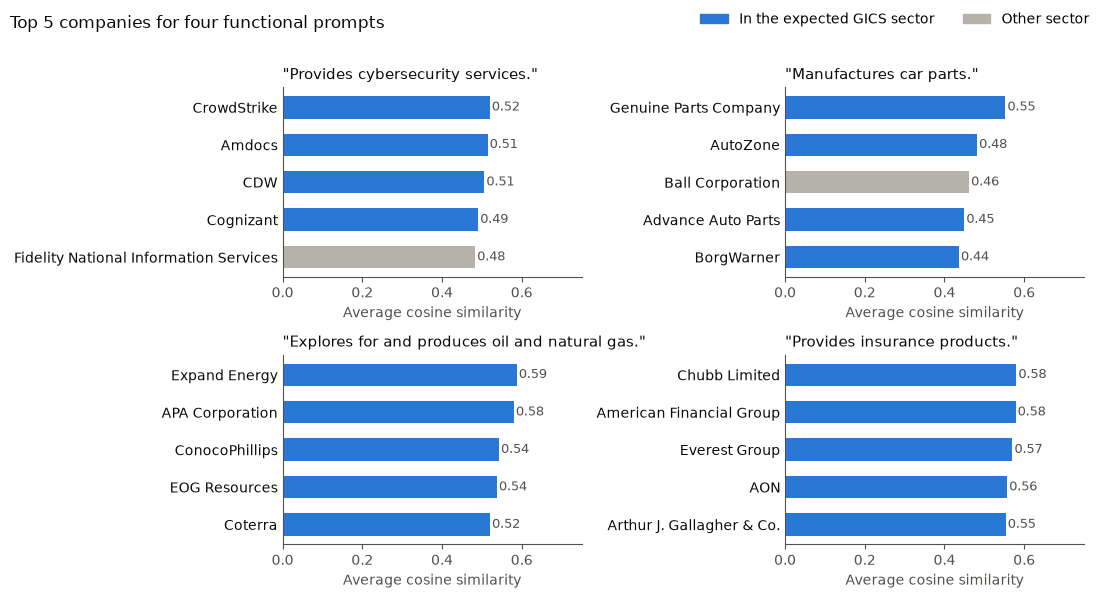

In [18]:
# Chart colors
MATCH_COLOR = "#2a78d6"
MISS_COLOR = "#b4b2a9"
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"

plt.rcParams.update({
    "font.size": 10,
    "axes.edgecolor": MUTED_COLOR,
    "axes.labelcolor": MUTED_COLOR,
    "xtick.color": MUTED_COLOR,
    "ytick.color": TEXT_COLOR,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Top 5 companies for four example prompts
example_queries = [
    "Provides cybersecurity services.",
    "Manufactures car parts.",
    "Explores for and produces oil and natural gas.",
    "Provides insurance products.",
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, example_query in zip(axes.flat, example_queries):
    top5 = top_results[example_query].head(5).iloc[::-1]
    colors = [MATCH_COLOR if hit else MISS_COLOR for hit in top5["in_expected_sector"]]
    ax.barh(top5["company_name"], top5["average_similarity"], color=colors, height=0.6)
    for y, score in enumerate(top5["average_similarity"]):
        ax.text(score + 0.005, y, f"{score:.2f}", va="center", fontsize=9, color=MUTED_COLOR)
    ax.set_title(f'"{example_query}"', loc="left", fontsize=10.5, color=TEXT_COLOR)
    ax.set_xlim(0, 0.75)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Average cosine similarity")

handles = [
    plt.Rectangle((0, 0), 1, 1, color=MATCH_COLOR),
    plt.Rectangle((0, 0), 1, 1, color=MISS_COLOR),
]
fig.legend(handles, ["In the expected GICS sector", "Other sector"], loc="upper right", frameon=False, ncol=2)
fig.suptitle("Top 5 companies for four functional prompts", x=0.01, ha="left", fontsize=12, color=TEXT_COLOR)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(os.path.join(images_dir, "top_matches.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

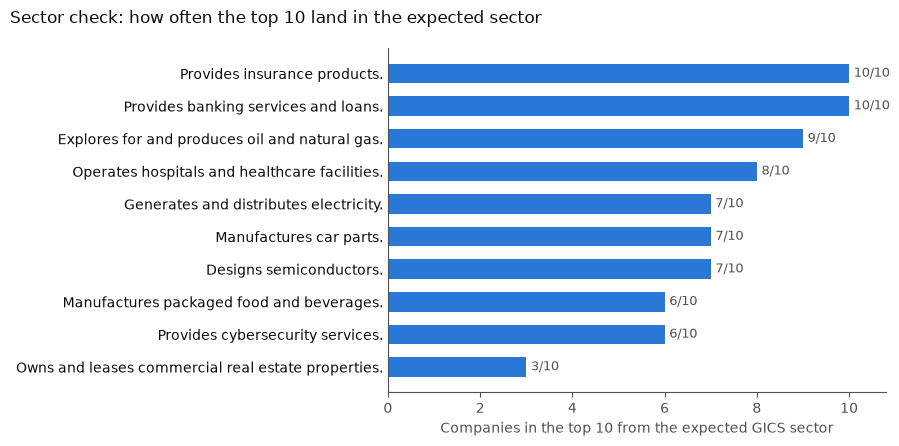

In [19]:
# Share of the top 10 in the expected sector, per prompt
plot_df = sector_check.sort_values("hits_in_top_10")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_df["query"], plot_df["hits_in_top_10"], color=MATCH_COLOR, height=0.6)
for y, hits in enumerate(plot_df["hits_in_top_10"]):
    ax.text(hits + 0.1, y, f"{hits}/{TOP_K}", va="center", fontsize=9, color=MUTED_COLOR)
ax.set_xlim(0, TOP_K + 0.8)
ax.set_xticks(range(0, TOP_K + 1, 2))
ax.tick_params(axis="y", length=0)
ax.set_xlabel(f"Companies in the top {TOP_K} from the expected GICS sector")
fig.suptitle("Sector check: how often the top 10 land in the expected sector", x=0.01, ha="left", fontsize=12, color=TEXT_COLOR)
fig.tight_layout()
fig.savefig(os.path.join(images_dir, "sector_check.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 7. Conclusion

The pipeline splits 424 business descriptions into 2,800 sentences, keeps the 2,267 that describe what the company does, and ranks companies against a plain-English prompt by their average sentence similarity.

- For "Provides cybersecurity services.", CrowdStrike comes first (0.52), followed by IT software and services companies (Amdocs, CDW, Cognizant).
- Across the ten test prompts, 73% of the top 10 companies are in the GICS sector the prompt points to. Banking and insurance get 10/10 and oil and gas gets 9/10.
- Some misses are reasonable near matches. Packaging makers (Ball, Berry Global, Crown Holdings, Amcor) show up for the packaged food and beverages prompt, and Ball also shows up for car parts.
- The real estate prompt is the weakest (3/10). Its top 10 scores are low and bunched together (0.36 to 0.39), so the search can't separate the REITs from banks and utilities.

Things to improve:

- The data is a partial pull of the Russell 1000 (424 companies, almost all A to G), so the search only covers that subset.
- Averaging over every sentence favors companies whose whole description is on topic and can bury a company where only one segment matches. Ranking on each company's best few sentences is worth testing.
- Pre-filtering by sector or financial metrics would narrow the search for specific use cases and cut down the number of sentences to score.